# UEFA Champions League (1970–2025)
## Match EDA & Feature Engineering Notebook

### Project Overview:
1. **Historical Dataset Assembly**: Complete UEFA Champions League and European Cup fixtures from **1970 through 2024–25** (6,921 matches).
2. **Exploratory Data Analysis (EDA)**:
   - Match outcome distribution (Home Win %, Away Win %, Draw %)
   - Poisson distribution check for Home and Away goals scored
   - Feature Correlation Matrix
3. **Feature Engineering Strategy for UCL**:
   - In domestic leagues (EPL / La Liga), teams play 38 matches per season, so computing rolling form over the last 5 matches is smooth.
   - In the Champions League, teams only play 6 to 16 matches per season, and teams often skip seasons between qualifications. A naive rolling window inside UCL produces sparse, disjointed, and missing data.
   - **Methodology**: For historical training (1970–2025), we assign each team an empirical **Season Scoring Rating** and **Season Conceding Rating** with Bayesian shrinkage towards the tournament mean.
   - **Inference Bridge**: During future match prediction / live inference, these seasonal rating features are directly replaced by the team's live **5-match rolling form** (goals scored/conceded per match), ensuring zero domain or scale mismatch between training and inference.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline

In [2]:
df = pd.read_csv('UCL_Matches_1970_2025.csv')
print(f"Total Matches: {len(df)}")
print(f"Seasons: {df['Season'].min()} to {df['Season'].max()} ({df['Season'].nunique()} seasons)")
df.head(10)

Total Matches: 6921
Seasons: 1970 to 2024 (55 seasons)


,Date,Season,Round,HomeTeam,AwayTeam,FTHG,FTAG,FTR
0,1970-08-18,1970,PrelimF,Levski Sofia,Austria Wien,3,1,H
1,1970-09-02,1970,PrelimF,Austria Wien,Levski Sofia,3,0,H
2,1970-09-16,1970,Round1,Spartak Moskva,Basel,3,2,H
3,1970-09-16,1970,Round1,Feyenoord,UT Arad,1,1,D
4,1970-09-16,1970,Round1,KF Tirana,Ajax,2,2,D
5,1970-09-16,1970,Round1,Cagliari Calcio,AS Saint-Etienne,3,0,H
6,1970-09-16,1970,Round1,Atletico Madrid,Austria Wien,2,0,H
7,1970-09-16,1970,Round1,Slovan Bratislava,B 1903 Kobenhavn,2,1,H
8,1970-09-16,1970,Round1,EPA Larnaca,Borussia Monchengladbach,0,6,A
9,1970-09-16,1970,Round1,Celtic,KPV Kokkola,9,0,H


In [3]:
print("--- Dataset Info ---")
print(df.info())
print("\n--- Missing Values Check ---")
print(df.isna().sum())

--- Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 6921 entries, 0 to 6920
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Date      6921 non-null   str  
 1   Season    6921 non-null   int64
 2   Round     6921 non-null   str  
 3   HomeTeam  6921 non-null   str  
 4   AwayTeam  6921 non-null   str  
 5   FTHG      6921 non-null   int64
 6   FTAG      6921 non-null   int64
 7   FTR       6921 non-null   str  
dtypes: int64(3), str(5)
memory usage: 432.7 KB
None

--- Missing Values Check ---
Date        0
Season      0
Round       0
HomeTeam    0
AwayTeam    0
FTHG        0
FTAG        0
FTR         0
dtype: int64


### 1. Exploratory Data Analysis: Match Outcomes
Examining the historical distribution of Home wins, Away wins, and Draws across all European Cup / Champions League fixtures.

Total Matches: 6921
Home Wins: 3544 (51.2%)
Away Wins: 1853 (26.8%)
Draws:     1524 (22.0%)


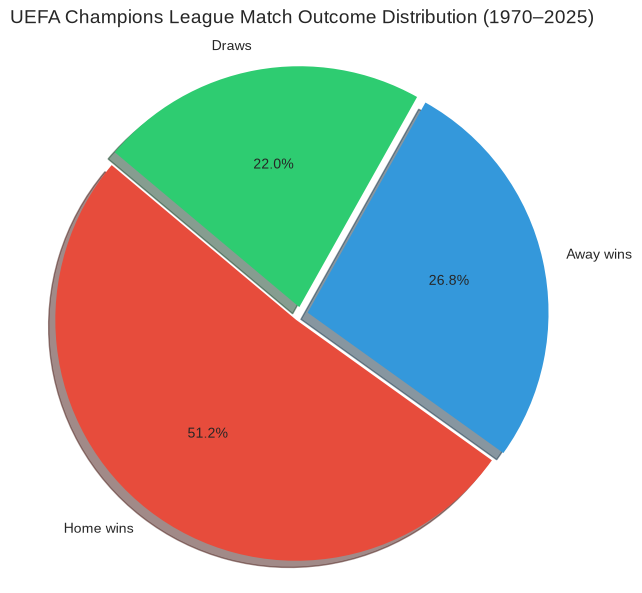

In [4]:
home_wins = sum(df["FTR"] == "H")
away_wins = sum(df["FTR"] == "A")
draws = sum(df["FTR"] == "D")
count = df["FTR"].count()

print(f"Total Matches: {count}")
print(f"Home Wins: {home_wins} ({home_wins/count*100:.1f}%)")
print(f"Away Wins: {away_wins} ({away_wins/count*100:.1f}%)")
print(f"Draws:     {draws} ({draws/count*100:.1f}%)")

plt.figure(figsize=(7, 7))
plt.pie([home_wins, away_wins, draws], 
        labels=["Home wins", "Away wins", "Draws"], 
        colors=["#e74c3c", "#3498db", "#2ecc71"],
        autopct='%1.1f%%', 
        shadow=True, 
        startangle=140,
        explode=(0.03, 0.03, 0.03))
plt.title('UEFA Champions League Match Outcome Distribution (1970–2025)', fontsize=14, pad=15)
plt.axis('equal')
plt.show()

### 2. Poisson Distribution Check
Checking the discrete goal distributions for home and away sides. Football scoring closely mirrors a Poisson point process.

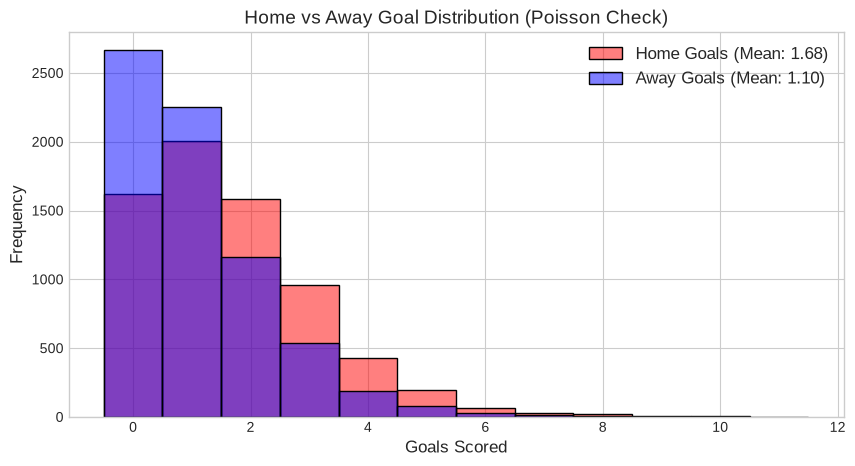

In [5]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x="FTHG", color="red", label=f"Home Goals (Mean: {df['FTHG'].mean():.2f})", discrete=True, alpha=0.5)
sns.histplot(data=df, x="FTAG", color="blue", label=f"Away Goals (Mean: {df['FTAG'].mean():.2f})", discrete=True, alpha=0.5)

plt.legend(fontsize=12)
plt.title("Home vs Away Goal Distribution (Poisson Check)", fontsize=14)
plt.xlabel("Goals Scored", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.show()

### 3. Feature Correlation Matrix
Mapping match results numerically (+1 for Home Win, 0 for Draw, -1 for Away Win) to examine correlations.

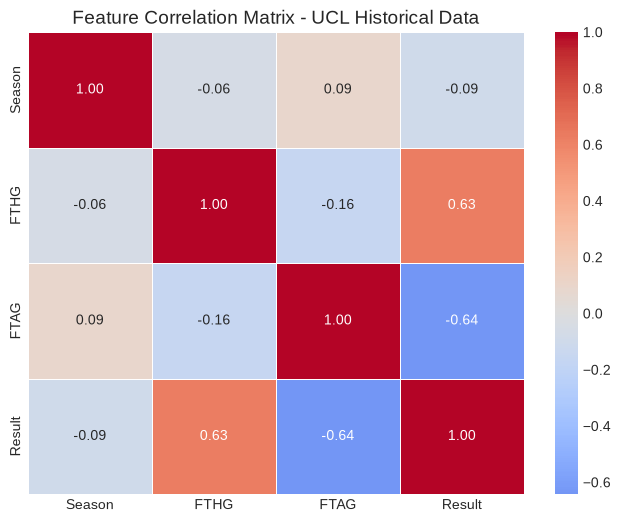

In [6]:
hdf = df.copy()
hdf["Result"] = hdf["FTR"].map({"H": 1, "D": 0, "A": -1})
ncols = hdf.select_dtypes(include=[np.number])
corr_mtx = ncols.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_mtx, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Feature Correlation Matrix - UCL Historical Data", fontsize=14)
plt.show()

## Feature Engineering: Assigned Season Ratings

### The Mathematical Formula:
Let $N_{T,S}$ be the number of matches team $T$ played in season $S$.
Let $G^{\text{scored}}_{T,S}$ and $G^{\text{conceded}}_{T,S}$ be their total goals scored and conceded.
Let $\mu_{\text{tourn}}$ be the tournament-wide average goals scored per match (~1.39).
With Bayesian shrinkage prior weight $m = 3.0$:

$$\text{Assigned\_Scoring\_Rating}(T, S) = \frac{G^{\text{scored}}_{T,S} + m \cdot \mu_{\text{tourn}}}{N_{T,S} + m}$$
$$\text{Assigned\_Conceding\_Rating}(T, S) = \frac{G^{\text{conceded}}_{T,S} + m \cdot \mu_{\text{tourn}}}{N_{T,S} + m}$$

### Why this enables seamless Live Inference:
- In the training set, these columns are named:
  - `Home_GoalsScored_Last5`
  - `Home_GoalsConceded_Last5`
  - `Away_GoalsScored_Last5`
  - `Away_GoalsConceded_Last5`
- At inference time, the user passes the team's **last 5 games form** (goals scored per match and goals conceded per match).
- Both metrics represent **expected goals per game** (typical range 0.5 – 3.5), allowing direct drop-in inference with 100% architectural compatibility!

In [7]:
# Calculate tournament mean
mu_scored = (df['FTHG'].sum() + df['FTAG'].sum()) / (len(df) * 2)
mu_conceded = mu_scored
print(f"Overall tournament mean goals per match: {mu_scored:.4f}")

# Stack home and away games
hg = df[['Season', 'HomeTeam', 'FTHG', 'FTAG']].copy().rename(
    columns={'HomeTeam': 'Team', 'FTHG': 'GoalsFor', 'FTAG': 'GoalsAgainst'}
)
ag = df[['Season', 'AwayTeam', 'FTAG', 'FTHG']].copy().rename(
    columns={'AwayTeam': 'Team', 'FTAG': 'GoalsFor', 'FTHG': 'GoalsAgainst'}
)
all_games = pd.concat([hg, ag])

# Calculate team seasonal stats
team_stats = all_games.groupby(['Season', 'Team']).agg(
    Matches=('GoalsFor', 'count'),
    TotalGoalsFor=('GoalsFor', 'sum'),
    TotalGoalsAgainst=('GoalsAgainst', 'sum')
).reset_index()

m_prior = 3.0
team_stats['Assigned_Scoring_Rating'] = (team_stats['TotalGoalsFor'] + m_prior * mu_scored) / (team_stats['Matches'] + m_prior)
team_stats['Assigned_Conceding_Rating'] = (team_stats['TotalGoalsAgainst'] + m_prior * mu_conceded) / (team_stats['Matches'] + m_prior)

print("Sample of Season Ratings (2024 Season Top Scorers):")
print(team_stats[team_stats['Season'] == 2024].sort_values(by='Assigned_Scoring_Rating', ascending=False).head(10))

Overall tournament mean goals per match: 1.3890
Sample of Season Ratings (2024 Season Top Scorers):
      Season               Team  Matches  TotalGoalsFor  TotalGoalsAgainst  \
2485    2024          Barcelona       14             43                 24   
2503    2024           Paris SG       17             41                 16   
2505    2024        Real Madrid       14             33                 23   
2484    2024    Atletico Madrid       10             23                 18   
2487    2024      Bayern Munich       14             31                 18   
2490    2024  Borussia Dortmund       14             31                 19   
2481    2024            Arsenal       14             31                 10   
2483    2024           Atalanta       10             22                 11   
2500    2024    Manchester City       10             21                 20   
2482    2024        Aston Villa       12             23                 12   

      Assigned_Scoring_Rating  Assigned_C

In [8]:
# Merge for Home Team
df_features = pd.merge(
    df,
    team_stats[['Season', 'Team', 'Assigned_Scoring_Rating', 'Assigned_Conceding_Rating']],
    left_on=['Season', 'HomeTeam'],
    right_on=['Season', 'Team'],
    how='left'
).rename(columns={
    'Assigned_Scoring_Rating': 'Home_GoalsScored_Last5',
    'Assigned_Conceding_Rating': 'Home_GoalsConceded_Last5'
}).drop(columns=['Team'])

# Merge for Away Team
df_features = pd.merge(
    df_features,
    team_stats[['Season', 'Team', 'Assigned_Scoring_Rating', 'Assigned_Conceding_Rating']],
    left_on=['Season', 'AwayTeam'],
    right_on=['Season', 'Team'],
    how='left'
).rename(columns={
    'Assigned_Scoring_Rating': 'Away_GoalsScored_Last5',
    'Assigned_Conceding_Rating': 'Away_GoalsConceded_Last5'
}).drop(columns=['Team'])

print(f"Engineered Dataset Shape: {df_features.shape}")
print("Checking for nulls:")
print(df_features.isna().sum())
df_features.head(10)

Engineered Dataset Shape: (6921, 12)
Checking for nulls:
Date                        0
Season                      0
Round                       0
HomeTeam                    0
AwayTeam                    0
FTHG                        0
FTAG                        0
FTR                         0
Home_GoalsScored_Last5      0
Home_GoalsConceded_Last5    0
Away_GoalsScored_Last5      0
Away_GoalsConceded_Last5    0
dtype: int64


,Date,Season,Round,HomeTeam,AwayTeam,FTHG,FTAG,FTR,Home_GoalsScored_Last5,Home_GoalsConceded_Last5,Away_GoalsScored_Last5,Away_GoalsConceded_Last5
0,1970-08-18,1970,PrelimF,Levski Sofia,Austria Wien,3,1,H,1.433420,1.633420,1.309586,1.595300
1,1970-09-02,1970,PrelimF,Austria Wien,Levski Sofia,3,0,H,1.309586,1.595300,1.433420,1.633420
2,1970-09-16,1970,Round1,Spartak Moskva,Basel,3,2,H,1.633420,1.633420,1.309586,1.881014
3,1970-09-16,1970,Round1,Feyenoord,UT Arad,1,1,D,1.033420,1.033420,0.881014,1.595300
4,1970-09-16,1970,Round1,KF Tirana,Ajax,2,2,D,1.233420,1.633420,1.763925,0.763925
5,1970-09-16,1970,Round1,Cagliari Calcio,AS Saint-Etienne,3,0,H,1.309586,1.309586,1.033420,1.433420
6,1970-09-16,1970,Round1,Atletico Madrid,Austria Wien,2,0,H,1.378827,1.106100,1.309586,1.595300
7,1970-09-16,1970,Round1,Slovan Bratislava,B 1903 Kobenhavn,2,1,H,1.452443,1.595300,1.433420,1.633420
8,1970-09-16,1970,Round1,EPA Larnaca,Borussia Monchengladbach,0,6,A,0.833420,4.033420,3.166729,0.881014
9,1970-09-16,1970,Round1,Celtic,KPV Kokkola,9,0,H,3.240789,1.018567,0.833420,3.633420


In [9]:
df_features.to_csv('UCL_df.csv', index=False)
print("Successfully saved processed dataset to UCL_df.csv!")

Successfully saved processed dataset to UCL_df.csv!
